# 从复指数与向量投影到离散傅里叶变换

先比较实向量和复向量上的投影，再手算四点 DFT，并逐项与 NumPy 的 FFT 对照。

## 复指数的旋转、实部、虚部与递推

In [1]:
import numpy as np

# 复向量的长度
A = 1.0

# 每前进一个样本，角度增加 pi/4 弧度
omega = np.pi / 4

# 初始角度
phi = 0.0

# 样本编号：0, 1, ..., 8
n = np.arange(9)

# 每个样本对应的角度
theta = omega * n + phi

# 生成复指数序列
z = A * np.exp(1j * theta)

# 分别取出实部与虚部
real_part = z.real
imag_part = z.imag

print("复数序列：", np.round(z, 3))
print("实部：", np.round(real_part, 3))
print("虚部：", np.round(imag_part, 3))
print("模长：", np.abs(z))

复数序列： [ 1.   +0.j     0.707+0.707j  0.   +1.j    -0.707+0.707j -1.   +0.j
 -0.707-0.707j -0.   -1.j     0.707-0.707j  1.   -0.j   ]
实部： [ 1.     0.707  0.    -0.707 -1.    -0.707 -0.     0.707  1.   ]
虚部： [ 0.     0.707  1.     0.707  0.    -0.707 -1.    -0.707 -0.   ]
模长： [1. 1. 1. 1. 1. 1. 1. 1. 1.]


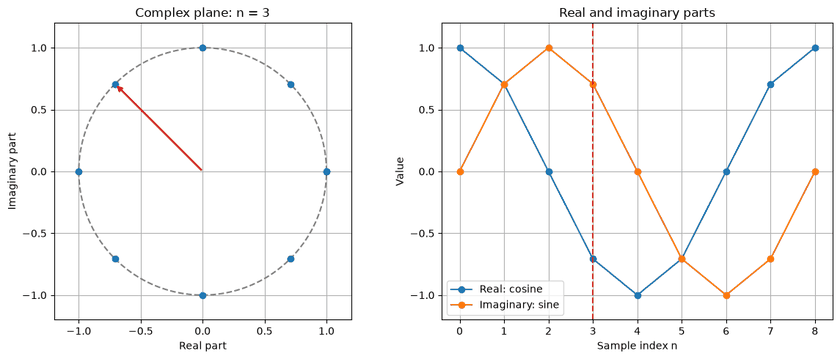

In [2]:
import matplotlib.pyplot as plt

# 用较密的角度画一个参考圆
circle_angles = np.linspace(0, 2 * np.pi, 400)
circle = A * np.exp(1j * circle_angles)

# 选中第 3 个编号的样本，即 z[3]
selected = 3
point = z[selected]

# 创建左右两个绘图区
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# 左图：参考圆
axes[0].plot(
    circle.real,
    circle.imag,
    color="gray",
    linestyle="--"
)

# 左图：复指数的各个采样点
axes[0].plot(
    real_part,
    imag_part,
    marker="o",
    linestyle="None",
    color="tab:blue"
)

# 左图：从原点指向选中样本的箭头
axes[0].annotate(
    "",
    xy=(point.real, point.imag),
    xytext=(0, 0),
    arrowprops={
        "arrowstyle": "->",
        "color": "tab:red",
        "linewidth": 2
    }
)

axes[0].set_title(f"Complex plane: n = {selected}")
axes[0].set_xlabel("Real part")
axes[0].set_ylabel("Imaginary part")

axes[0].set_xlim(-1.2 * A, 1.2 * A)
axes[0].set_ylim(-1.2 * A, 1.2 * A)
axes[0].set_aspect("equal")

# 右图：实部随样本编号的变化
axes[1].plot(
    n,
    real_part,
    marker="o",
    linestyle="-",
    color="tab:blue",
    label="Real: cosine"
)

# 右图：虚部随样本编号的变化
axes[1].plot(
    n,
    imag_part,
    marker="o",
    linestyle="-",
    color="tab:orange",
    label="Imaginary: sine"
)

# 右图：标出当前选中的样本编号
axes[1].axvline(
    n[selected],
    color="tab:red",
    linestyle="--"
)

axes[1].set_title("Real and imaginary parts")
axes[1].set_xlabel("Sample index n")
axes[1].set_ylabel("Value")
axes[1].set_ylim(-1.2 * A, 1.2 * A)
axes[1].legend()

for ax in axes:
    ax.grid(True)

plt.tight_layout()
plt.show()

In [3]:
# 每一步使用的旋转系数
rotation = np.exp(1j * omega)

# 必须使用复数数组，才能同时保存实部和虚部
z_step = np.zeros(len(n), dtype=complex)

# 给定初始位置
z_step[0] = A * np.exp(1j * phi)

# 从第二个样本开始，用上一个样本生成当前样本
for i in range(1, len(n)):
    z_step[i] = rotation * z_step[i - 1]

print(np.round(z_step, 3))

[ 1.   +0.j     0.707+0.707j  0.   +1.j    -0.707+0.707j -1.   +0.j
 -0.707-0.707j  0.   -1.j     0.707-0.707j  1.   +0.j   ]


## 离散周期与混叠

In [4]:
import numpy as np

# 预期的周期：8 个样本
P = 8

# 生成两个周期所需的样本编号：0, 1, ..., 15
n_period = np.arange(2 * P)

# 每一步转 3*pi/4 弧度
omega_period = 3 * np.pi / 4

# 生成复指数序列
z_period = np.exp(1j * omega_period * n_period)

# 取出前后两个长度为 8 的数据块
first_block = z_period[:P]
second_block = z_period[P:2 * P]

print("第一块：", np.round(first_block, 3))
print("第二块：", np.round(second_block, 3))

# 检查对应位置的复数是否在数值误差范围内相同
same = np.allclose(
    first_block,
    second_block,
    rtol=0,
    atol=1e-10
)

print("两块是否相同：", same)

第一块： [ 1.   +0.j    -0.707+0.707j -0.   -1.j     0.707+0.707j -1.   +0.j
  0.707-0.707j  0.   +1.j    -0.707-0.707j]
第二块： [ 1.   -0.j    -0.707+0.707j -0.   -1.j     0.707+0.707j -1.   +0.j
  0.707-0.707j -0.   +1.j    -0.707-0.707j]
两块是否相同： True


In [5]:
# 用相同的样本编号比较两个频率
n_alias = np.arange(16)

# 每步转 45°
omega_a = np.pi / 4

# 每步转 405°：比前者多一整圈
omega_b = omega_a + 2 * np.pi

z_a = np.exp(1j * omega_a * n_alias)
z_b = np.exp(1j * omega_b * n_alias)

same_samples = np.allclose(
    z_a,
    z_b,
    rtol=0,
    atol=1e-10
)

print("两种频率的样本是否相同：", same_samples)

两种频率的样本是否相同： True


采样值是否相同： True


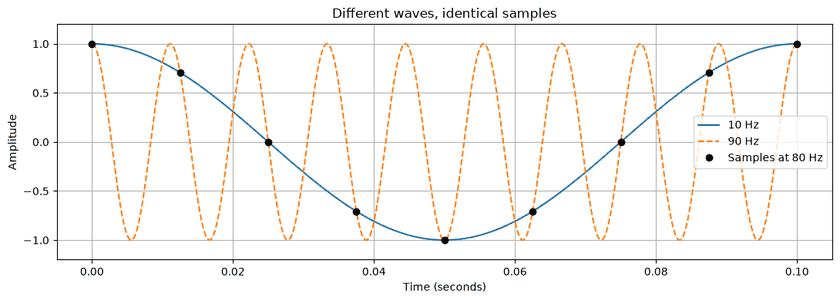

In [6]:
import matplotlib.pyplot as plt

# 实际采样率：每秒 80 个样本
fs = 80

# 两个连续信号的频率
f_low = 10
f_high = 90

# 用密集时间点画参考曲线
t_dense = np.linspace(0, 0.1, 1000)

# 实际采样位置：编号 0～8
n_sample = np.arange(9)

# 将样本编号换算成秒
t_sample = n_sample / fs

# 参考曲线：用于展示两种不同的连续波形
low_dense = np.cos(2 * np.pi * f_low * t_dense)
high_dense = np.cos(2 * np.pi * f_high * t_dense)

# 在实际采样时刻上计算数值
low_samples = np.cos(2 * np.pi * f_low * t_sample)
high_samples = np.cos(2 * np.pi * f_high * t_sample)

print(
    "采样值是否相同：",
    np.allclose(
        low_samples,
        high_samples,
        rtol=0,
        atol=1e-10
    )
)

# 创建一个绘图区
fig, ax = plt.subplots(figsize=(11, 4))

# 蓝色：10 Hz 参考曲线
ax.plot(
    t_dense,
    low_dense,
    color="tab:blue",
    label="10 Hz"
)

# 橙色：90 Hz 参考曲线
ax.plot(
    t_dense,
    high_dense,
    color="tab:orange",
    linestyle="--",
    label="90 Hz"
)

# 黑点：两种信号共有的采样值
ax.plot(
    t_sample,
    low_samples,
    marker="o",
    linestyle="None",
    color="black",
    label="Samples at 80 Hz"
)

ax.set_title("Different waves, identical samples")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.set_ylim(-1.2, 1.2)

ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

## 实向量投影与残差最小值

In [7]:
import numpy as np

# 原信号：四个时刻的采样值
x = np.array([3, 1, 3, 1], dtype=float)

# 参考波形：正、负、正、负交替
b = np.array([1, -1, 1, -1], dtype=float)

# 对应位置相乘
products = x * b

# 内积：对应位置相乘后求和
inner_product = np.dot(x, b)

# 参考向量的长度平方
b_squared_length = np.dot(b, b)

# 投影系数：参考波形应该乘多少倍
coefficient = inner_product / b_squared_length

# 投影向量
projection = coefficient * b

# 原信号中剩下的部分
residual = x - projection

print("逐项乘积：", products)
print("内积：", inner_product)
print("参考向量的长度平方：", b_squared_length)
print("投影系数：", coefficient)
print("投影向量：", projection)
print("残差：", residual)

逐项乘积： [ 3. -1.  3. -1.]
内积： 4.0
参考向量的长度平方： 4.0
投影系数： 1.0
投影向量： [ 1. -1.  1. -1.]
残差： [2. 2. 2. 2.]


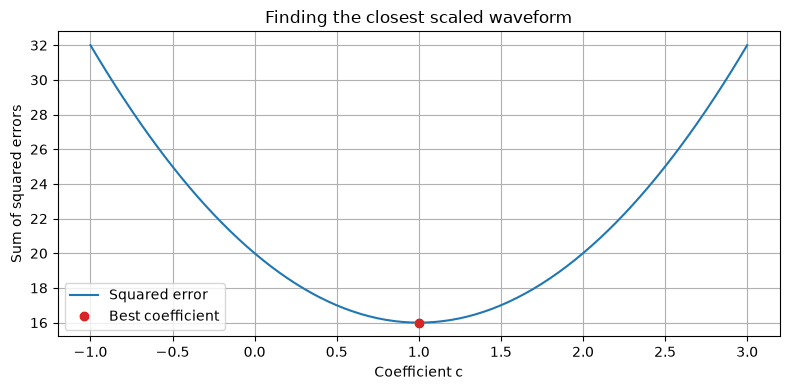

In [8]:
import matplotlib.pyplot as plt

# 从 -1 到 3，均匀选取 81 个候选倍数
coefficients = np.linspace(-1, 3, 81)

# 为每个候选倍数准备一个位置，存放它的误差
squared_errors = np.zeros_like(coefficients)

# 依次尝试每一个候选倍数
for i in range(len(coefficients)):
    trial_coefficient = coefficients[i]

    trial_projection = trial_coefficient * b
    trial_residual = x - trial_projection

    squared_errors[i] = np.dot(
        trial_residual,
        trial_residual
    )

# 最优投影的平方误差
best_error = np.dot(residual, residual)

# 创建一张图和一个绘图区
fig, ax = plt.subplots(figsize=(8, 4))

# 画出“倍数—误差”的关系
ax.plot(
    coefficients,
    squared_errors,
    color="tab:blue",
    label="Squared error"
)

# 标出公式算出来的最佳位置
ax.plot(
    coefficient,
    best_error,
    "o",
    color="tab:red",
    label="Best coefficient"
)

ax.set_xlabel("Coefficient c")
ax.set_ylabel("Sum of squared errors")
ax.set_title("Finding the closest scaled waveform")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

## 用四个正交基向量分解与还原信号

In [9]:
import numpy as np

# 一段四点信号
x = np.array([4, 2, 3, -1], dtype=float)

# 每一行是一个参考向量
basis = np.array(
    [
        [1,  1,  1,  1],
        [1, -1,  1, -1],
        [1,  1, -1, -1],
        [1, -1, -1,  1],
    ],
    dtype=float
)

# 为四个系数准备存储空间
coefficients = np.zeros(len(basis), dtype=float)

# 从全零信号开始，逐个加上投影分量
reconstructed = np.zeros_like(x)

for k in range(len(basis)):
    # 取出第 k 个参考向量
    b = basis[k]

    # 计算原信号在这个方向上的系数
    numerator = np.dot(x, b)
    denominator = np.dot(b, b)
    coefficient = numerator / denominator

    # 保存系数
    coefficients[k] = coefficient

    # 根据系数构造这一方向上的信号分量
    component = coefficient * b

    # 累加到重建结果中
    reconstructed = reconstructed + component

print("原信号：", x)
print("系数：", coefficients)
print("重建结果：", reconstructed)

same = np.allclose(
    x,
    reconstructed,
    rtol=0,
    atol=1e-10
)

print("是否成功还原：", same)

原信号： [ 4.  2.  3. -1.]
系数： [ 2.   1.5  1.  -0.5]
重建结果： [ 4.  2.  3. -1.]
是否成功还原： True


## 复内积、共轭与正交残差

In [10]:
import numpy as np

# 四个复数采样点
b = np.array([1, 1j, -1, -1j], dtype=complex)

# 对每个元素取共轭
conjugate_b = np.conj(b)

# 两种逐项乘法
ordinary_products = b * b
conjugate_products = conjugate_b * b

print("不取共轭的逐项乘积：", ordinary_products)
print("取共轭后的逐项乘积：", conjugate_products)

# 两种乘积求和
ordinary_sum = np.dot(b, b)
inner_product = np.vdot(b, b)

print("普通乘积求和：", ordinary_sum)
print("复数内积：", inner_product)

不取共轭的逐项乘积： [ 1.+0.j -1.+0.j  1.-0.j -1.+0.j]
取共轭后的逐项乘积： [1.+0.j 1.+0.j 1.+0.j 1.+0.j]
普通乘积求和： 0j
复数内积： (4+0j)


In [11]:
# 恒定分量
constant = np.array([1, 1, 1, 1], dtype=complex)

# 构造信号：复数倍的参考波形，加上恒定分量
x = (2 + 3j) * b + constant

# 参考向量放在前面，由 vdot 对它取共轭
numerator = np.vdot(b, x)
denominator = np.vdot(b, b)

# 求出投影系数
coefficient = numerator / denominator

# 构造投影，并计算残差
projection = coefficient * b
residual = x - projection

print("分子：", numerator)
print("分母：", denominator)
print("投影系数：", coefficient)
print("残差：", residual)
print("参考方向与残差的内积：", np.vdot(b, residual))

# 检查交换参数顺序会发生什么
print("交换顺序后的内积：", np.vdot(x, b))

分子： (8+12j)
分母： (4+0j)
投影系数： (2+3j)
残差： [1.+0.j 1.+0.j 1.+0.j 1.+0.j]
参考方向与残差的内积： 0j
交换顺序后的内积： (8-12j)


## 复指数基上的四点重建

In [12]:
import numpy as np

# 每段信号包含四个采样点
N = 4

# 四个采样位置：0、1、2、3
n = np.arange(N)

# 四行、四列，每行保存一个参考波形
basis = np.zeros((N, N), dtype=complex)

for k in range(N):
    # 第 k 个参考波形，每一步增加的角度
    omega = 2 * np.pi * k / N

    # 它在四个采样位置上的角度
    angles = omega * n

    # 由角度生成单位圆上的复数，保存到第 k 行
    basis[k] = np.exp(1j * angles)

print(np.round(basis, 3))

[[ 1.+0.j  1.+0.j  1.+0.j  1.+0.j]
 [ 1.+0.j  0.+1.j -1.+0.j -0.-1.j]
 [ 1.+0.j -1.+0.j  1.-0.j -1.+0.j]
 [ 1.+0.j -0.-1.j -1.+0.j  0.+1.j]]


In [13]:
# 待分析的四点信号
x = np.array(
    [3 + 3j, -2 + 2j, -1 - 3j, 4 - 2j],
    dtype=complex
)

# 保存四个复数系数
coefficients = np.zeros(N, dtype=complex)

# 从全零信号开始，逐项重建
reconstructed = np.zeros(N, dtype=complex)

for k in range(N):
    # 取出第 k 个参考波形
    reference = basis[k]

    # 在基向量上投影
    numerator = np.vdot(reference, x)
    denominator = np.vdot(reference, reference)

    coefficients[k] = numerator / denominator

    # 将当前方向上的分量加回去
    component = coefficients[k] * reference
    reconstructed = reconstructed + component

print("系数：", np.round(coefficients, 3))
print("重建结果：", np.round(reconstructed, 3))

same = np.allclose(
    x,
    reconstructed,
    rtol=0,
    atol=1e-10
)

print("是否还原成功：", same)

系数： [1.+0.j 2.+3.j 0.-0.j 0.-0.j]
重建结果： [ 3.+3.j -2.+2.j -1.-3.j  4.-2.j]
是否还原成功： True


## 手算 DFT 并与 FFT 及逆变换对照

In [14]:
import numpy as np

# 四点测试信号
x = np.array(
    [3 + 3j, -2 + 2j, -1 - 3j, 4 - 2j],
    dtype=complex
)

N = len(x)
n = np.arange(N)

# 保存参考波形和 DFT 输出
basis = np.zeros((N, N), dtype=complex)
X_manual = np.zeros(N, dtype=complex)

for k in range(N):
    # 生成第 k 个参考波形
    omega = 2 * np.pi * k / N
    basis[k] = np.exp(1j * omega * n)

    # DFT 输出直接保存内积，这里不除以 N
    X_manual[k] = np.vdot(basis[k], x)

# 换算为用于重建的系数
coefficients = X_manual / N

# 用 DFT 输出加权，最后统一除以 N
unscaled_sum = np.zeros(N, dtype=complex)

for k in range(N):
    unscaled_sum = unscaled_sum + X_manual[k] * basis[k]

x_manual = unscaled_sum / N

print("DFT 输出：", np.round(X_manual, 3))
print("投影系数：", np.round(coefficients, 3))
print("重建信号：", np.round(x_manual, 3))

DFT 输出： [4. +0.j 8.+12.j 0. -0.j 0. -0.j]
投影系数： [1.+0.j 2.+3.j 0.-0.j 0.-0.j]
重建信号： [ 3.+3.j -2.+2.j -1.-3.j  4.-2.j]


In [15]:
# 用 FFT 算法计算 DFT
X_fft = np.fft.fft(x)

# 用逆变换恢复原信号
x_ifft = np.fft.ifft(X_fft)

print("FFT 输出：", np.round(X_fft, 3))
print("逆变换结果：", np.round(x_ifft, 3))

print(
    "与手动 DFT 是否一致：",
    np.allclose(X_fft, X_manual, rtol=0, atol=1e-10)
)

print(
    "是否恢复原信号：",
    np.allclose(x_ifft, x, rtol=0, atol=1e-10)
)

FFT 输出： [4. +0.j 8.+12.j 0. +0.j 0. +0.j]
逆变换结果： [ 3.+3.j -2.+2.j -1.-3.j  4.-2.j]
与手动 DFT 是否一致： True
是否恢复原信号： True
